In [ ]:

import random
import math
import statistics
import matplotlib.pyplot as plt

def naive_market_maker(Spreads,seed):
    rng = random.Random(seed)
    SpreadsProfit = []
    for spread in Spreads: 
        for i in range(100):
            fair_price = 100.0
            inventory = 0
            cash = 0.0
            max_inventory = 10
            total_profit = 0.0
            losses = 0
            for t in range(1000):
                # The market price moves randomly
                fair_price += random.gauss(0, 0.2)

                bid = fair_price - spread / 2
                ask = fair_price + spread / 2

                # A customer arrives and either buys or sells
                customer = random.choice(["buy", "sell"])

                if customer == "buy" and inventory > -max_inventory:
                    # Customer buys from us at our ask
                    inventory -= 1
                    cash += ask

                elif customer == "sell" and inventory < max_inventory:
                    # Customer sells to us at our bid
                    inventory += 1
                    cash -= bid
                pnl = cash + inventory * fair_price
            total_profit += pnl
            if pnl < 0:
                losses += 1
        SpreadsProfit.append(total_profit / 100)
        print(f"Spread = {spread}:", round(total_profit, 2))
        print(f"Losses = {losses} out of 100 runs",round(losses/100,2))
    return SpreadsProfit

print("Final fair price:", round(fair_price, 2))
print("Final inventory:", inventory)
print("Cash:", round(cash, 2))
print("Profit/loss:", round(pnl, 2))

Final fair price: 171.41
Final inventory: 0
Cash: 250771.25
Profit/loss: 250771.25


In [277]:
def improved_market_maker(Spreads,seed,volatility=.2,trade_steps=1000,spread_steps=100,customer_uncertainty=.8,informed_fraction=.1,informed_trade_probability=.65):
    rng = random.Random(seed)
    SpreadsProfit = []
    AvgTrades = []
    SpreadsLossRate = []
    PnlStdevs = []
    for spread in Spreads: 
        total_profit = 0.0
        total_trades = 0
        losses = 0
        run_pnls = []
        for i in range(spread_steps):
            fair_price = 100.0
            inventory = 0
            cash = 0.0
            max_inventory = 10
            order_flow_bias = .4
            arrival_sensitivity = .7
            trades = 0
            pnl = 0
            transaction_cost = .02
            for t in range(trade_steps):
                price_change = rng.gauss(0, volatility)

                bid = fair_price - spread / 2
                ask = fair_price + spread / 2

                arrival_prob = math.exp(-arrival_sensitivity * spread)
                if rng.random() < arrival_prob:
                    if rng.random() < informed_fraction:
                        if price_change > 0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 + order_flow_bias)
                            else:
                                buy_probability = (.5 - order_flow_bias)
                        elif price_change <0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 - order_flow_bias)
                            else:
                                buy_probability = (.5 + order_flow_bias)
                        else:
                            buy_probability = .5
                        if rng.random() < buy_probability and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif rng.random() >= buy_probability and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                    else:
                        customer_min_surplus = .05
                        customer_value = fair_price + rng.gauss(0, customer_uncertainty)
                        buy_surplus = customer_value - ask
                        sell_surplus = bid - customer_value
                        if buy_surplus > customer_min_surplus and buy_surplus >= sell_surplus and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif sell_surplus > customer_min_surplus and sell_surplus > buy_surplus and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                fair_price += price_change
            pnl += cash + inventory * fair_price
            run_pnls.append(pnl)
            total_profit += pnl

            if pnl < 0:
                losses += 1
            
            total_trades += trades
        average_trades = total_trades / spread_steps
        loss_rate = losses / spread_steps
        SpreadsLossRate.append(loss_rate)
        SpreadsProfit.append(total_profit / spread_steps)
        AvgTrades.append(average_trades)
        PnlStdevs.append(statistics.stdev(run_pnls))
    return SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs

# Market Maker Simulation

## Objective
Investigate how bid-ask spread affects profitability, total trades, and loss percentage

## Parameters
 - Default volatility = .2
 - Default steps = 1000
 - Default informed percentage = .5

# Effects of Volatility
Volatility ranges from .2 to .8

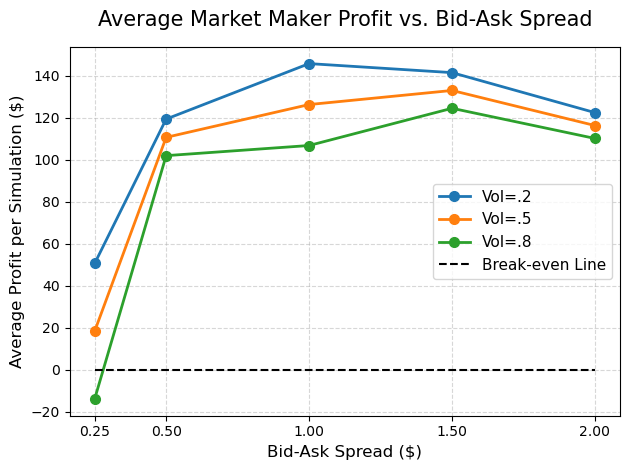

In [278]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='Vol=.2')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.5,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='Vol=.5')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.8,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='Vol=.8')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Average Market Maker Profit vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()


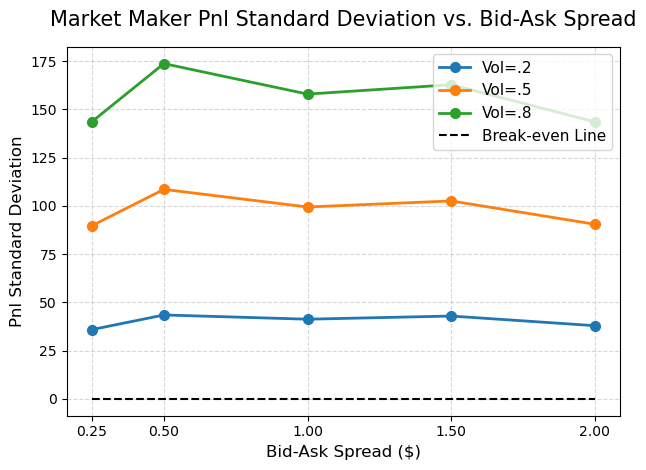

In [283]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='Vol=.2')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.5,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='Vol=.5')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.8,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='Vol=.8')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Market Maker Pnl Standard Deviation vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Pnl Standard Deviation', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="upper right",fontsize=11)

plt.tight_layout()
plt.show()

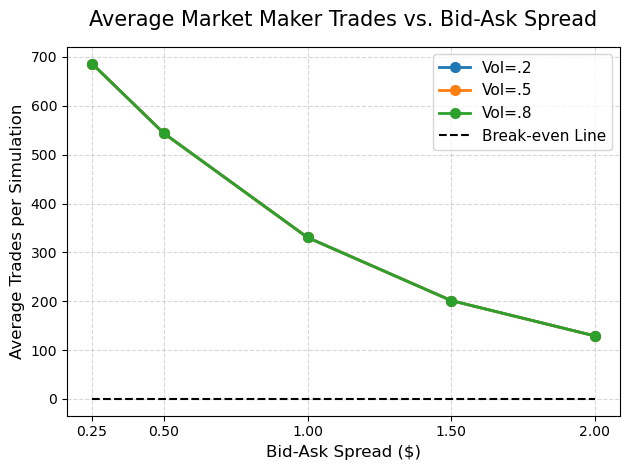

In [279]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='Vol=.2')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.5,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='Vol=.5')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.8,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='Vol=.8')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Average Market Maker Trades vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Trades per Simulation', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

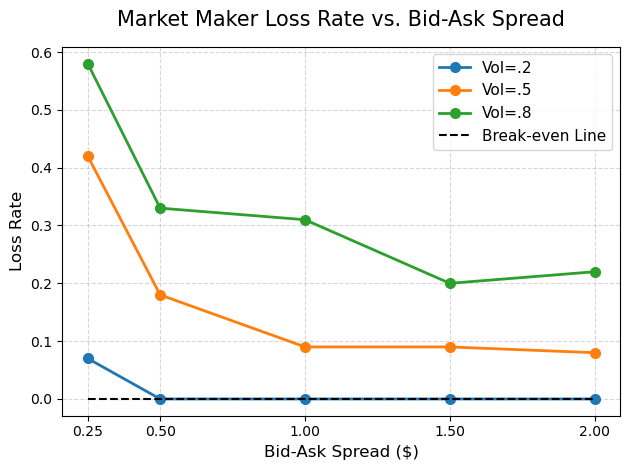

In [280]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.2,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='Vol=.2')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.5,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='Vol=.5')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, volatility=.8,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='Vol=.8')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Market Maker Loss Rate vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Loss Rate', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

# Effects of # Trade Steps
Trade steps range from 1000 to 3000

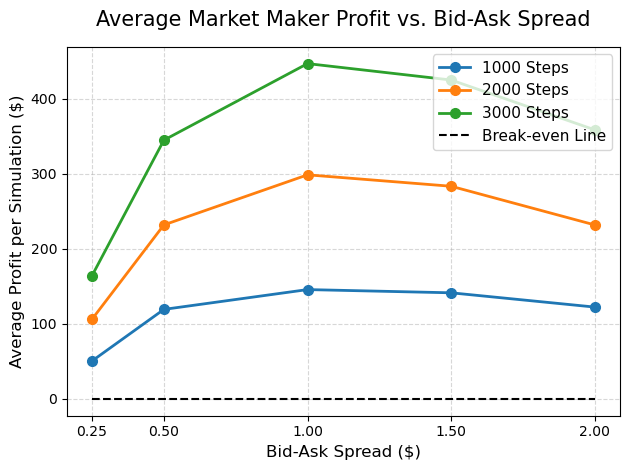

In [284]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='1000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=2000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='2000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=3000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='3000 Steps')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Average Market Maker Profit vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()


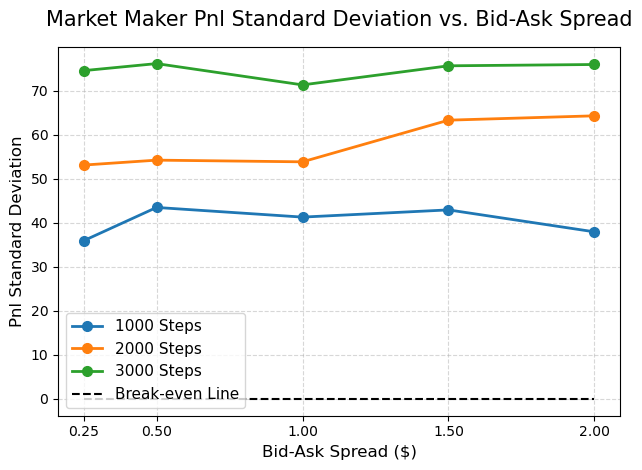

In [286]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='1000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=2000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='2000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=3000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='3000 Steps')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Market Maker Pnl Standard Deviation vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Pnl Standard Deviation', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="lower left", fontsize=11)

plt.tight_layout()
plt.show()

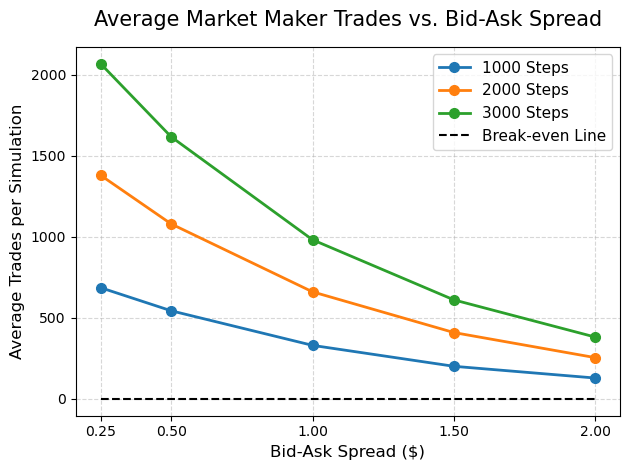

In [287]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='1000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=2000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='2000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=3000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='3000 Steps')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Average Market Maker Trades vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Trades per Simulation', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

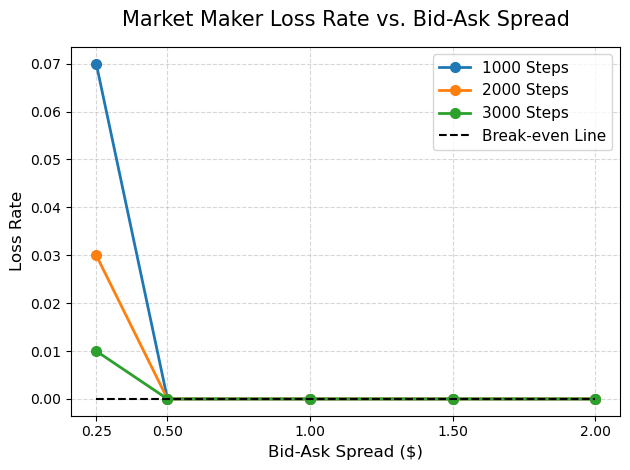

In [288]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='1000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=2000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='2000 Steps')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=3000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='3000 Steps')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Market Maker Loss Rate vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Loss Rate', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

# Effects of Informed Customers
Informed percentage ranges from .1 to .5

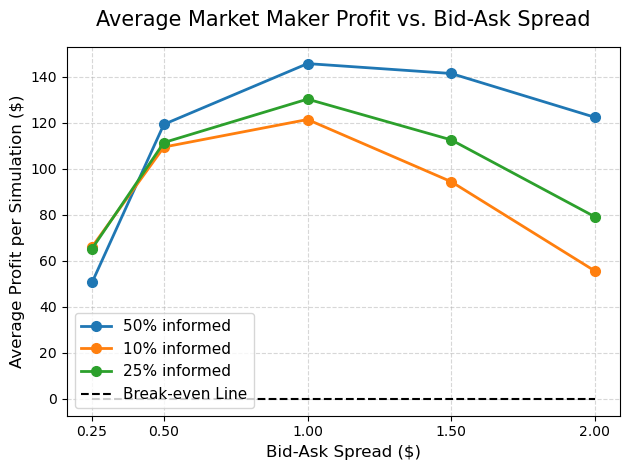

In [289]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='50% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.1, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='10% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.25, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsProfit, marker='o',markersize=7,linewidth=2,label='25% informed   ')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Average Market Maker Profit vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Profit per Simulation ($)', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="lower left", fontsize=11)

plt.tight_layout()
plt.show()

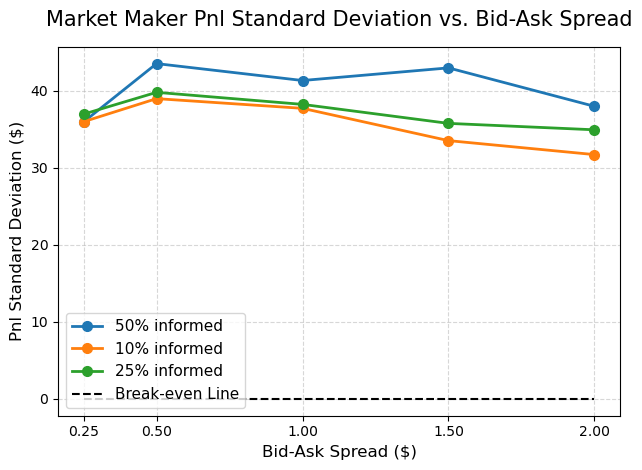

In [292]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='50% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.1, informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='10% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.25, informed_trade_probability=.65)
plt.plot(Spreads, PnlStdevs, marker='o',markersize=7,linewidth=2,label='25% informed   ')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Market Maker Pnl Standard Deviation vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Pnl Standard Deviation ($)', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="lower left", fontsize=11)

plt.tight_layout()
plt.show()

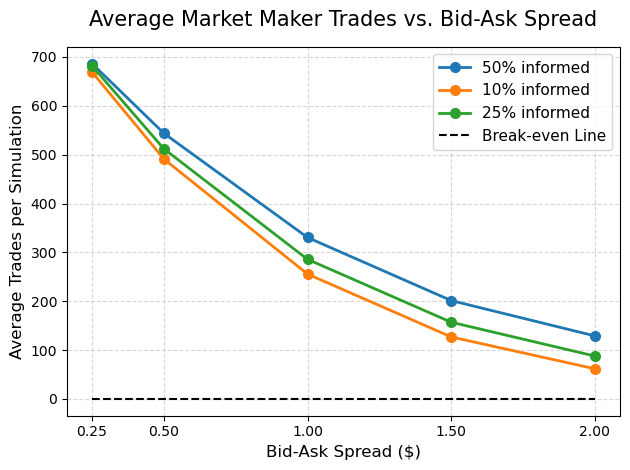

In [290]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='50% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.1, informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='10% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.25, informed_trade_probability=.65)
plt.plot(Spreads, AvgTrades, marker='o',markersize=7,linewidth=2,label='25% informed   ')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Average Market Maker Trades vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Average Trades per Simulation', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()

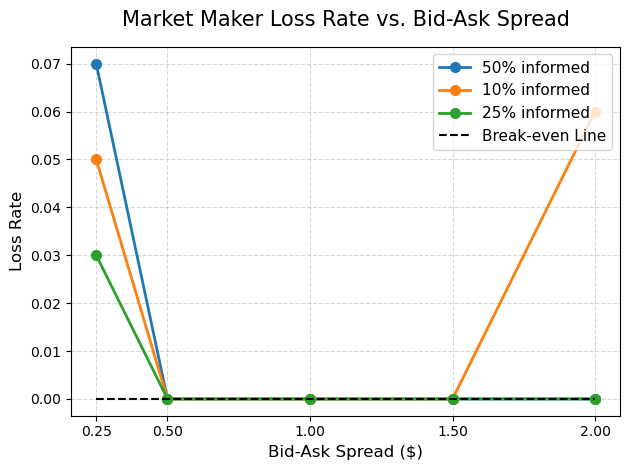

In [291]:
Spreads = [.25,.5,1.0,1.5,2.0]
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.5, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='50% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.1, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='10% informed')
SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(Spreads, seed=42, trade_steps=1000, customer_uncertainty=.8, informed_fraction=.25, informed_trade_probability=.65)
plt.plot(Spreads, SpreadsLossRate, marker='o',markersize=7,linewidth=2,label='25% informed   ')
plt.plot(Spreads,[0]*len(Spreads), linestyle='--', color='black', label='Break-even Line')
plt.title('Market Maker Loss Rate vs. Bid-Ask Spread',fontsize=15,pad=15)
plt.xlabel('Bid-Ask Spread ($)', fontsize=12)
plt.ylabel('Loss Rate', fontsize=12)

plt.xticks(Spreads)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()